# Experimento 14 — Seleção individual de features com TabPFN

Partimos das 26 features e das três melhores configurações TabPFN M/W do Exp. 13.
**Hiperparâmetros fixos; variam somente os subconjuntos de features.** Sem AutoML,
sem outra busca de configurações e sem combinações de grupos do futuro Exp. 15.

Protocolo: Season < ano → validação em 2023, 2024 e 2025, pesos de similaridade
originais, masculino e feminino separados. Seleção exclusivamente por RMSE ponderado;
Logistic Brier é diagnóstico. Os anos usados na seleção **não são teste independente**.

O resultado Kaggle 0,04753 do Top 3 do Exp. 13, informado anteriormente, é contexto
histórico; não entra em nenhuma escolha. [Documentação](../../docs/exp14.md).


In [1]:
from pathlib import Path
import sys
from html import escape
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

atual=Path.cwd().resolve()
raiz=next(p for p in [atual,*atual.parents] if (p/'raw_data').is_dir())
if str(raiz) not in sys.path:
    sys.path.insert(0,str(raiz))
from src import exp11 as comum, exp14 as exp

SEED=42
ANOS=[2023,2024,2025]
FEATURES=list(exp.FEATURES)
ORIGEM=raiz/'checkpoints'/'exp13'
CHECKPOINTS=raiz/'checkpoints'/'exp14'
RODAR_PILOTO=True
RODAR_ANALISE_COMPLETA=True
RODAR_PROGRESSIVA=True
GERAR_SUBMISSIONS=True
PILOTO_FEATURES=['RecentWinRate10Diff','RecentAvgMargin10Diff']
PILOTO_CONFIGURACOES_POR_CATEGORIA=1
MAX_AVALIACOES_POR_CONFIGURACAO=100  # Subconjuntos únicos, cada um com três cortes; controle excluído.
MAX_FEATURES_REMOVIDAS=10
MIN_FEATURES=5
MELHORA_MINIMA_RMSE=.001
REPETIR_FALHAS=False
MOSTRAR_LOG_AVALIACOES=False
assert len(FEATURES)==26
display(comum.versoes())


{'h2o': '3.46.0.12',
 'tabpfn': '9.2.0',
 'torch': '2.11.0+cu128',
 'numpy': '2.2.6',
 'pandas': '2.3.2',
 'scikit-learn': '1.7.1',
 'psutil': '7.2.2'}

## Origem e apresentação dos Tops

As seis configurações são lidas dos checkpoints do Exp. 13. Falta de arquivos,
inconsistência de parâmetros ou ranking divergente interrompe a leitura.
Cada Top mostra a quantidade de features; abra os detalhes para ver os nomes,
sem colocar listas de 26 atributos em uma tabela muito larga.


In [2]:
def mostrar_top(tabela,titulo):
    display(Markdown('### '+titulo))
    if tabela.empty:
        print('Nenhuma combinação com os três anos válidos ainda.'); return
    for cat,nome in [('M','Masculino'),('W','Feminino')]:
        top=tabela.loc[tabela.Categoria.eq(cat)&tabela.Posicao.le(3)].sort_values('Posicao')
        display(Markdown('**'+nome+' ('+cat+')**'))
        if top.empty:
            print('Sem combinações completas.'); continue
        colunas=['Posicao','Configuracao','NFeatures','NRemovidas','RMSE_pond','LB_pond',
                 'Delta_RMSE_pond','Delta_LB_pond']
        display(top[[c for c in colunas if c in top]].reset_index(drop=True))
        for r in top.to_dict('records'):
            mantidas=', '.join(r['Features'])
            removidas=', '.join(r.get('Removidas',[])) or 'Nenhuma'
            display(HTML('<details><summary>'+escape(f"Top {r['Posicao']} — {r['NFeatures']} features — {r['Configuracao']}")+
                '</summary><p><strong>Mantidas:</strong> '+escape(mantidas)+
                '</p><p><strong>Removidas:</strong> '+escape(removidas)+'</p></details>'))

def salvar_tabela(nome,tabela):
    registros=tabela.astype(object).where(tabela.notna(),None).to_dict('records')
    comum.salvar_json(CHECKPOINTS/nome,registros)

manifesto=exp.carregar_origem(ORIGEM)
catalogo=manifesto['candidatos']
REFERENCIAS=manifesto['referencias']
top13=manifesto['top13']
mostrar_top(top13,'Referência: Top 3 do Exp. 13, com 26 features')
display(REFERENCIAS)
display(pd.DataFrame(catalogo)[['Categoria','Candidato','Familia','Parametros']])
comum.salvar_json(CHECKPOINTS/'origem.json',{**manifesto,'referencias':REFERENCIAS.to_dict('records'),
    'top13':top13.to_dict('records')})


### Referência: Top 3 do Exp. 13, com 26 features

**Masculino (M)**

,Posicao,Configuracao,NFeatures,NRemovidas,RMSE_pond,LB_pond
0,1,M_tabpfn12_2973465e4981a4f7,26,0,12.104871,0.073467
1,2,M_tabpfn12_2c5a2f66d71abdc7,26,0,12.104900,0.073470
2,3,M_tabpfn12_33d31c0be877a927,26,0,12.105004,0.073467


**Feminino (W)**

,Posicao,Configuracao,NFeatures,NRemovidas,RMSE_pond,LB_pond
0,1,W_tabpfn12_d1eec64c5c3daa7d,26,0,12.382968,0.050571
1,2,W_tabpfn12_66abb88e8a794c6e,26,0,12.384055,0.050985
2,3,W_tabpfn12_a727afef5f6e5059,26,0,12.384869,0.050554


,Season,Distancia,Peso
0,2025,7.624698,0.374675
1,2024,8.193139,0.348680
2,2023,10.326554,0.276645


,Categoria,Candidato,Familia,Parametros
0,M,M_tabpfn12_2973465e4981a4f7,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r..."
1,M,M_tabpfn12_2c5a2f66d71abdc7,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r..."
2,M,M_tabpfn12_33d31c0be877a927,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r..."
3,W,W_tabpfn12_d1eec64c5c3daa7d,V3_5,"{'version': 'V3_5', 'n_estimators': 4, 'random..."
4,W,W_tabpfn12_66abb88e8a794c6e,V3_5,"{'version': 'V3_5', 'n_estimators': 4, 'random..."
5,W,W_tabpfn12_a727afef5f6e5059,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 8, 'r..."


## Preparação e controle equivalente

O mesmo preparo do Exp. 13: todas as features são pré-NCAA e diferenças A − B.
M: 2003+, W: 2010+; 2026: DayNum < 134. O controle só é importado se configuração,
dados, features, versões e protocolo forem equivalentes. Esta célula não treina;
controles ausentes serão ajustados apenas quando uma etapa habilitada precisar deles.


In [3]:
preparacao=exp.preparar_dados(raiz/'raw_data')
jogos=preparacao['jogos']
confrontos,sample=preparacao['confrontos'],preparacao['sample']
display(preparacao['auditoria'])
for cat,tabela in jogos.items():
    assert tabela.TeamA.lt(tabela.TeamB).all()
    np.testing.assert_allclose(tabela.Target,tabela.ScoreA-tabela.ScoreB)
    assert np.isfinite(tabela[FEATURES].to_numpy()).all()
    display(pd.DataFrame({'Categoria':cat,'NaN':tabela[FEATURES].isna().sum(),
        'Inf':np.isinf(tabela[FEATURES].to_numpy()).sum(axis=0)},index=FEATURES))

avaliador=exp.Avaliador(jogos,catalogo,REFERENCIAS,pasta=CHECKPOINTS,pasta_exp13=ORIGEM,
    max_avaliacoes_por_configuracao=MAX_AVALIACOES_POR_CONFIGURACAO,repetir_falhas=REPETIR_FALHAS,
    verbose=MOSTRAR_LOG_AVALIACOES)
auditoria_controle=avaliador.auditar_controle()
display(auditoria_controle.groupby(['Categoria','Status']).size().rename('Cortes'))
controles_reutilizados=avaliador.reutilizar_controles()
print('Configurações com controle completo reutilizado sem fit:',len(controles_reutilizados),'/ 6')
salvar_tabela('auditoria_controle.json',auditoria_controle)


,Categoria,JogosTreinoHistorico,PrimeiroAno,UltimoAno,FontesFeatures,Limite2026,SemSobreposicaoNCAA,JogosDetalhados2026,UltimoDayNum2026
0,M,1449,2003,2025,RegularSeasonCompactResults + RegularSeasonDet...,134,True,5647,132
1,W,961,2010,2025,RegularSeasonCompactResults + RegularSeasonDet...,134,True,5479,132


,Categoria,NaN,Inf
SeedDif,M,0,0
WinRateDiff,M,0,0
AvgPointsForDiff,M,0,0
AvgPointsAgainstDiff,M,0,0
OppWinRateDiff,M,0,0
FGPercentageDiff,M,0,0
ThreePointPercentageDiff,M,0,0
FTPercentageDiff,M,0,0
AssistsPerGameDiff,M,0,0
OffensiveReboundsPerGameDiff,M,0,0


,Categoria,NaN,Inf
SeedDif,W,0,0
WinRateDiff,W,0,0
AvgPointsForDiff,W,0,0
AvgPointsAgainstDiff,W,0,0
OppWinRateDiff,W,0,0
FGPercentageDiff,W,0,0
ThreePointPercentageDiff,W,0,0
FTPercentageDiff,W,0,0
AssistsPerGameDiff,W,0,0
OffensiveReboundsPerGameDiff,W,0,0


Categoria  Status       
M          compativel_ok    9
W          compativel_ok    9
Name: Cortes, dtype: int64

Configurações com controle completo reutilizado sem fit: 6 / 6


## Execução por etapas

O padrão roda somente o piloto: duas remoções, na configuração Top 1 de M e W
(quatro subconjuntos, 12 ajustes históricos, além de controles incompatíveis).
Para testar outro piloto, altere PILOTO_FEATURES ou o número de configurações.
TabPFN roda sequencialmente na GPU, com autenticação e filtro específico herdados.
Nenhum servidor H2O é iniciado.

O limite de avaliações é **por configuração**, cumulativo entre piloto, análise
completa e progressiva. Um subconjunto conta uma avaliação com três cortes,
inclusive se falhar ou for interrompido; o controle de 26 features não conta.
O padrão 100 permite até 600 subconjuntos / 1.800 ajustes para as seis configurações.
Isso é um teto de contagem, não um limite de tempo. Para continuar, aumente o limite
ou use None; os fits já concluídos serão reaproveitados.
Para acompanhar cada avaliação na saída, habilite MOSTRAR_LOG_AVALIACOES.


In [4]:
if RODAR_PILOTO or RODAR_ANALISE_COMPLETA or RODAR_PROGRESSIVA or GERAR_SUBMISSIONS:
    ambiente=comum.detectar_tabpfn(exigir_gpu=True)
    comum.carregar_token_tabpfn(raiz/'.env.tabpfn')
    display(comum.validar_acesso_tabpfn(),ambiente)
    comum.salvar_json(CHECKPOINTS/'ambiente.json',{'tabpfn':ambiente,'versoes':comum.versoes()})

if RODAR_PILOTO:
    assert 1<=PILOTO_CONFIGURACOES_POR_CATEGORIA<=3
    ids_piloto=top13.loc[top13.Posicao.le(PILOTO_CONFIGURACOES_POR_CATEGORIA),'Configuracao'].tolist()
    piloto=exp.avaliar_individuais(avaliador,features=PILOTO_FEATURES,configuracoes=ids_piloto,piloto=True)
    display(piloto.drop(columns='Features'))
    salvar_tabela('piloto.json',piloto)
else:
    print('Piloto desativado.')
display(avaliador.contagem())


{'chave_valida': True,
 'licenca': 'tabpfn-3-5-license-v1.0',
 'licenca_aceita': True}

{'device': 'cuda:0',
 'cuda': '12.8',
 'gpu': 'NVIDIA GeForce RTX 3060',
 'vram_gb': 11.99951171875,
 'versoes': {'h2o': '3.46.0.12',
  'tabpfn': '9.2.0',
  'torch': '2.11.0+cu128',
  'numpy': '2.2.6',
  'pandas': '2.3.2',
  'scikit-learn': '1.7.1',
  'psutil': '7.2.2'}}

,Categoria,Configuracao,FeatureRemovida,Avaliacao,NFeatures,status,RMSE_controle,RMSE_sem,LB_controle,LB_sem,Delta_RMSE,Delta_LB,Impacto,PosicaoImpacto
0,M,M_tabpfn12_2973465e4981a4f7,RecentAvgMargin10Diff,M_tabpfn12_2973465e4981a4f7__f01f0c6011d329a50,25,ok,12.104871,12.119154,0.073467,0.073952,0.014283,0.000485,piorou,1
1,M,M_tabpfn12_2973465e4981a4f7,RecentWinRate10Diff,M_tabpfn12_2973465e4981a4f7__f60fb92879c3cfbe2,25,ok,12.104871,12.122493,0.073467,0.074407,0.017622,0.000940,piorou,2
2,W,W_tabpfn12_d1eec64c5c3daa7d,RecentAvgMargin10Diff,W_tabpfn12_d1eec64c5c3daa7d__f01f0c6011d329a50,25,ok,12.382968,12.384521,0.050571,0.050375,0.001553,-0.000196,piorou,1
3,W,W_tabpfn12_d1eec64c5c3daa7d,RecentWinRate10Diff,W_tabpfn12_d1eec64c5c3daa7d__f60fb92879c3cfbe2,25,ok,12.382968,12.406305,0.050571,0.050233,0.023338,-0.000338,piorou,2


,Categoria,Configuracao,AvaliacoesUsadas,Limite
0,M,M_tabpfn12_2973465e4981a4f7,2,100
1,M,M_tabpfn12_2c5a2f66d71abdc7,0,100
2,M,M_tabpfn12_33d31c0be877a927,0,100
3,W,W_tabpfn12_d1eec64c5c3daa7d,2,100
4,W,W_tabpfn12_66abb88e8a794c6e,0,100
5,W,W_tabpfn12_a727afef5f6e5059,0,100


## Etapa A — Remoção individual

Habilite RODAR_ANALISE_COMPLETA=True para as 26 remoções em cada configuração.
São 156 subconjuntos / 468 ajustes históricos, aproveitando o piloto.
Cada teste recomeça com as 26 features e remove **somente uma**; a importância
é específica da configuração. Delta negativo indica que remover melhorou o RMSE.


Testes  Melhoraram
Categoria Configuracao                                   
M         M_tabpfn12_2973465e4981a4f7      26          10
          M_tabpfn12_2c5a2f66d71abdc7      26          10
          M_tabpfn12_33d31c0be877a927      26          10
W         W_tabpfn12_66abb88e8a794c6e      26           3
          W_tabpfn12_a727afef5f6e5059      26           9
          W_tabpfn12_d1eec64c5c3daa7d      26          15

PosicaoImpacto,FeatureRemovida,NFeatures,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,Delta_LB,Impacto,status
1,FGPercentageDiff,25,12.104871,12.068467,-0.036404,0.073467,0.072992,-0.000475,melhorou,ok
2,AssistsPerGameDiff,25,12.104871,12.079643,-0.025228,0.073467,0.073032,-0.000435,melhorou,ok
3,OppWinRateDiff,25,12.104871,12.086487,-0.018384,0.073467,0.074027,0.000560,melhorou,ok
4,OffensiveReboundsPerGameDiff,25,12.104871,12.089295,-0.015576,0.073467,0.073423,-0.000044,melhorou,ok
5,StealsPerGameDiff,25,12.104871,12.093540,-0.011330,0.073467,0.073193,-0.000274,melhorou,ok
6,DefensiveReboundsPerGameDiff,25,12.104871,12.100432,-0.004439,0.073467,0.073494,0.000027,melhorou,ok
7,WinRateDiff,25,12.104871,12.100586,-0.004285,0.073467,0.073973,0.000506,melhorou,ok
8,DefensiveRatingDiff,25,12.104871,12.102923,-0.001948,0.073467,0.073789,0.000322,melhorou,ok
9,RecentAvgPointsFor10Diff,25,12.104871,12.103600,-0.001271,0.073467,0.073714,0.000247,melhorou,ok
10,TurnoverRateDiff,25,12.104871,12.104060,-0.000811,0.073467,0.073725,0.000258,melhorou,ok


PosicaoImpacto,FeatureRemovida,NFeatures,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,Delta_LB,Impacto,status
1,FGPercentageDiff,25,12.1049,12.069204,-0.035696,0.07347,0.073004,-0.000466,melhorou,ok
2,AssistsPerGameDiff,25,12.1049,12.080823,-0.024078,0.07347,0.073044,-0.000426,melhorou,ok
3,OppWinRateDiff,25,12.1049,12.086292,-0.018608,0.07347,0.074019,0.000549,melhorou,ok
4,OffensiveReboundsPerGameDiff,25,12.1049,12.089468,-0.015432,0.07347,0.073426,-0.000044,melhorou,ok
5,StealsPerGameDiff,25,12.1049,12.093546,-0.011355,0.07347,0.073192,-0.000278,melhorou,ok
6,DefensiveReboundsPerGameDiff,25,12.1049,12.100784,-0.004117,0.07347,0.073498,0.000028,melhorou,ok
7,WinRateDiff,25,12.1049,12.101058,-0.003843,0.07347,0.073973,0.000503,melhorou,ok
8,DefensiveRatingDiff,25,12.1049,12.102675,-0.002225,0.07347,0.073777,0.000307,melhorou,ok
9,TurnoverRateDiff,25,12.1049,12.103707,-0.001193,0.07347,0.073718,0.000248,melhorou,ok
10,RecentAvgPointsFor10Diff,25,12.1049,12.103852,-0.001048,0.07347,0.073713,0.000243,melhorou,ok


PosicaoImpacto,FeatureRemovida,NFeatures,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,Delta_LB,Impacto,status
1,FGPercentageDiff,25,12.105004,12.069089,-0.035914,0.073467,0.073004,-0.000462,melhorou,ok
2,AssistsPerGameDiff,25,12.105004,12.079881,-0.025122,0.073467,0.073032,-0.000434,melhorou,ok
3,OppWinRateDiff,25,12.105004,12.087224,-0.017779,0.073467,0.074048,0.000581,melhorou,ok
4,OffensiveReboundsPerGameDiff,25,12.105004,12.089619,-0.015385,0.073467,0.073427,-0.000040,melhorou,ok
5,StealsPerGameDiff,25,12.105004,12.093597,-0.011407,0.073467,0.073193,-0.000274,melhorou,ok
6,WinRateDiff,25,12.105004,12.100843,-0.004161,0.073467,0.073985,0.000519,melhorou,ok
7,DefensiveReboundsPerGameDiff,25,12.105004,12.100961,-0.004043,0.073467,0.073493,0.000026,melhorou,ok
8,DefensiveRatingDiff,25,12.105004,12.103147,-0.001857,0.073467,0.073796,0.000330,melhorou,ok
9,RecentAvgPointsFor10Diff,25,12.105004,12.103565,-0.001438,0.073467,0.073720,0.000254,melhorou,ok
10,TurnoverRateDiff,25,12.105004,12.103953,-0.001051,0.073467,0.073733,0.000266,melhorou,ok


PosicaoImpacto,FeatureRemovida,NFeatures,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,Delta_LB,Impacto,status
1,BlocksPerGameDiff,25,12.384055,12.337452,-0.046603,0.050985,0.049937,-0.001049,melhorou,ok
2,FreeThrowRateDiff,25,12.384055,12.375322,-0.008733,0.050985,0.050676,-0.000310,melhorou,ok
3,AvgPointsForDiff,25,12.384055,12.378823,-0.005232,0.050985,0.050638,-0.000347,melhorou,ok
4,FGPercentageDiff,25,12.384055,12.388162,0.004107,0.050985,0.050460,-0.000525,piorou,ok
5,AvgPointsAgainstDiff,25,12.384055,12.388905,0.004850,0.050985,0.050745,-0.000240,piorou,ok
6,DefensiveReboundsPerGameDiff,25,12.384055,12.388907,0.004852,0.050985,0.050394,-0.000591,piorou,ok
7,TurnoversPerGameDiff,25,12.384055,12.389362,0.005308,0.050985,0.050332,-0.000653,piorou,ok
8,TurnoverRateDiff,25,12.384055,12.389575,0.005520,0.050985,0.050604,-0.000381,piorou,ok
9,NetRatingDiff,25,12.384055,12.391990,0.007935,0.050985,0.050655,-0.000331,piorou,ok
10,EffectiveFGPercentageDiff,25,12.384055,12.393803,0.009748,0.050985,0.050527,-0.000458,piorou,ok


PosicaoImpacto,FeatureRemovida,NFeatures,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,Delta_LB,Impacto,status
1,FreeThrowRateDiff,25,12.384869,12.343725,-0.041143,0.050554,0.050230,-0.000324,melhorou,ok
2,BlocksPerGameDiff,25,12.384869,12.354376,-0.030493,0.050554,0.049590,-0.000964,melhorou,ok
3,AvgPointsAgainstDiff,25,12.384869,12.368089,-0.016779,0.050554,0.050502,-0.000052,melhorou,ok
4,TurnoverRateDiff,25,12.384869,12.376115,-0.008753,0.050554,0.050253,-0.000300,melhorou,ok
5,AvgPointsForDiff,25,12.384869,12.377545,-0.007324,0.050554,0.050180,-0.000374,melhorou,ok
6,FGPercentageDiff,25,12.384869,12.377588,-0.007281,0.050554,0.050300,-0.000254,melhorou,ok
7,RecentAvgPointsAgainst10Diff,25,12.384869,12.378842,-0.006027,0.050554,0.050304,-0.000250,melhorou,ok
8,NetRatingDiff,25,12.384869,12.383596,-0.001273,0.050554,0.050351,-0.000203,melhorou,ok
9,DefensiveRatingDiff,25,12.384869,12.384083,-0.000786,0.050554,0.050300,-0.000254,melhorou,ok
10,ThreePointPercentageDiff,25,12.384869,12.385050,0.000181,0.050554,0.050169,-0.000384,piorou,ok


PosicaoImpacto,FeatureRemovida,NFeatures,RMSE_controle,RMSE_sem,Delta_RMSE,LB_controle,LB_sem,Delta_LB,Impacto,status
1,BlocksPerGameDiff,25,12.382968,12.316705,-0.066263,0.050571,0.049631,-0.000940,melhorou,ok
2,FreeThrowRateDiff,25,12.382968,12.346128,-0.036839,0.050571,0.050404,-0.000167,melhorou,ok
3,DefensiveReboundsPerGameDiff,25,12.382968,12.354547,-0.028421,0.050571,0.049856,-0.000715,melhorou,ok
4,AvgPointsForDiff,25,12.382968,12.356047,-0.026921,0.050571,0.050162,-0.000409,melhorou,ok
5,NetRatingDiff,25,12.382968,12.357949,-0.025019,0.050571,0.050313,-0.000258,melhorou,ok
6,TurnoverRateDiff,25,12.382968,12.359699,-0.023268,0.050571,0.050262,-0.000309,melhorou,ok
7,EffectiveFGPercentageDiff,25,12.382968,12.364045,-0.018923,0.050571,0.050188,-0.000383,melhorou,ok
8,TurnoversPerGameDiff,25,12.382968,12.365131,-0.017836,0.050571,0.049838,-0.000733,melhorou,ok
9,FGPercentageDiff,25,12.382968,12.371001,-0.011966,0.050571,0.050032,-0.000539,melhorou,ok
10,StealsPerGameDiff,25,12.382968,12.373701,-0.009267,0.050571,0.050325,-0.000245,melhorou,ok


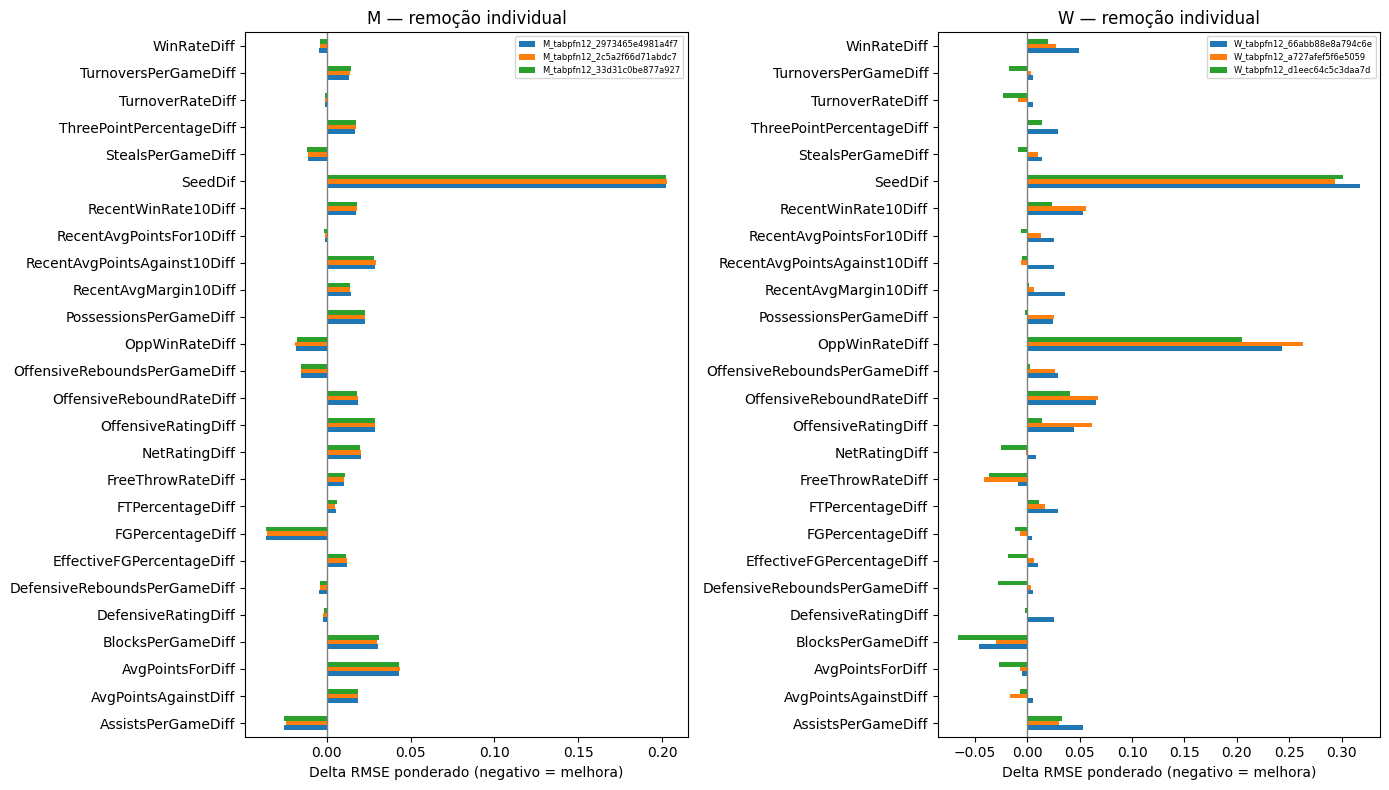

In [5]:
if RODAR_ANALISE_COMPLETA:
    individuais=exp.avaliar_individuais(avaliador)
    salvar_tabela('analise_individual.json',individuais)
    display(individuais.assign(Melhorou=individuais.Impacto.eq('melhorou')).groupby(
        ['Categoria','Configuracao']).agg(Testes=('FeatureRemovida','size'),Melhoraram=('Melhorou','sum')))
    colunas=['PosicaoImpacto','FeatureRemovida','NFeatures','RMSE_controle','RMSE_sem',
             'Delta_RMSE','LB_controle','LB_sem','Delta_LB','Impacto','status']
    for (cat,ident),grupo in individuais.groupby(['Categoria','Configuracao'],sort=False):
        display(HTML('<details><summary>'+escape(f'{cat} — {ident}: ranking das 26 remoções')+
            '</summary>'+grupo[colunas].to_html(index=False,escape=True)+'</details>'))
    fig,axes=plt.subplots(1,2,figsize=(14,8))
    for ax,cat in zip(axes,['M','W']):
        plot=individuais.loc[individuais.Categoria.eq(cat)].pivot(
            index='FeatureRemovida',columns='Configuracao',values='Delta_RMSE')
        plot.plot.barh(ax=ax)
        ax.axvline(0,color='gray',linewidth=1)
        ax.set(title=cat+' — remoção individual',xlabel='Delta RMSE ponderado (negativo = melhora)',ylabel='')
        ax.legend(fontsize=6)
    plt.tight_layout(); plt.show()
else:
    print('Análise completa desativada; habilite-a depois de conferir o piloto.')


## Etapa B — Eliminação regressiva

Habilite RODAR_PROGRESSIVA=True depois de completar a análise individual.
Para cada configuração/categoria, testar uma remoção por vez no conjunto atual
e aceitar a maior melhora somente se superar MELHORA_MINIMA_RMSE.
Não há quantidade ideal predefinida: MAX_FEATURES_REMOVIDAS e MIN_FEATURES são limites.

Uma rodada parcial por orçamento fica pendente, sem aceitar uma escolha parcial.
Falhas são registradas e não concorrem; a escolha considera os testes válidos da
rodada concluída. Reiniciar esta etapa reconstitui a trajetória com checkpoints.


In [6]:
progressivas=[]
if RODAR_PROGRESSIVA:
    for c in catalogo:
        progressivas.append(exp.selecao_progressiva(avaliador,c['Candidato'],ativar=True,
            max_removidas=MAX_FEATURES_REMOVIDAS,min_features=MIN_FEATURES,melhora_minima=MELHORA_MINIMA_RMSE))
    resumo=pd.DataFrame([{k:r[k] for k in ['Categoria','Configuracao','NFeatures','NRemovidas',
        'RMSE_pond','LB_pond','Motivo']} for r in progressivas])
    display(resumo)
    for r in progressivas:
        display(HTML('<details><summary>'+escape(f"{r['Categoria']} — {r['Configuracao']}: {r['NFeatures']} features finais")+
            '</summary><p><strong>Mantidas:</strong> '+escape(', '.join(r['Features']))+
            '</p><p><strong>Removidas:</strong> '+escape(', '.join(r['Removidas']) or 'Nenhuma')+'</p></details>'))
        historia=pd.DataFrame([{k:v for k,v in rodada.items() if k not in ['Testes','FeaturesAntes']}
            for rodada in r['Rodadas']])
        if not historia.empty:
            display(historia)
    comum.salvar_json(CHECKPOINTS/'progressivas_resumo.json',progressivas)
else:
    print('Seleção progressiva desativada.')
display(avaliador.contagem())


,Categoria,Configuracao,NFeatures,NRemovidas,RMSE_pond,LB_pond,Motivo
0,M,M_tabpfn12_2973465e4981a4f7,22,4,11.992508,0.070264,orcamento_rodada_incompleta
1,M,M_tabpfn12_2c5a2f66d71abdc7,22,4,11.993744,0.070278,orcamento_rodada_incompleta
2,M,M_tabpfn12_33d31c0be877a927,22,4,11.992859,0.070264,orcamento_rodada_incompleta
3,W,W_tabpfn12_d1eec64c5c3daa7d,24,2,12.276338,0.049225,sem_melhora_minima
4,W,W_tabpfn12_66abb88e8a794c6e,24,2,12.270070,0.049438,sem_melhora_minima
5,W,W_tabpfn12_a727afef5f6e5059,23,3,12.300567,0.048695,sem_melhora_minima


,Rodada,Referencia,NFeaturesAntes,RMSE_antes,LB_antes,Aceita,Removida,MelhoraRMSE
0,1,M_tabpfn12_2973465e4981a4f7__ffc601c53ba08bbed,26,12.104871,0.073467,True,FGPercentageDiff,0.036404
1,2,M_tabpfn12_2973465e4981a4f7__fb557a1ea37349b3b,25,12.068467,0.072992,True,AssistsPerGameDiff,0.018852
2,3,M_tabpfn12_2973465e4981a4f7__fddad6f394c795fa3,24,12.049615,0.072411,True,DefensiveReboundsPerGameDiff,0.014373
3,4,M_tabpfn12_2973465e4981a4f7__f99af1c9e6f0030dd,23,12.035242,0.071841,True,StealsPerGameDiff,0.042734
4,5,M_tabpfn12_2973465e4981a4f7__fe739f291ba00fba1,22,11.992508,0.070264,False,None,NaN


,Rodada,Referencia,NFeaturesAntes,RMSE_antes,LB_antes,Aceita,Removida,MelhoraRMSE
0,1,M_tabpfn12_2c5a2f66d71abdc7__ffc601c53ba08bbed,26,12.104900,0.073470,True,FGPercentageDiff,0.035696
1,2,M_tabpfn12_2c5a2f66d71abdc7__fb557a1ea37349b3b,25,12.069204,0.073004,True,AssistsPerGameDiff,0.020315
2,3,M_tabpfn12_2c5a2f66d71abdc7__fddad6f394c795fa3,24,12.048889,0.072398,True,DefensiveReboundsPerGameDiff,0.013200
3,4,M_tabpfn12_2c5a2f66d71abdc7__f99af1c9e6f0030dd,23,12.035689,0.071844,True,StealsPerGameDiff,0.041945
4,5,M_tabpfn12_2c5a2f66d71abdc7__fe739f291ba00fba1,22,11.993744,0.070278,False,None,NaN


,Rodada,Referencia,NFeaturesAntes,RMSE_antes,LB_antes,Aceita,Removida,MelhoraRMSE
0,1,M_tabpfn12_33d31c0be877a927__ffc601c53ba08bbed,26,12.105004,0.073467,True,FGPercentageDiff,0.035914
1,2,M_tabpfn12_33d31c0be877a927__fb557a1ea37349b3b,25,12.069089,0.073004,True,AssistsPerGameDiff,0.019004
2,3,M_tabpfn12_33d31c0be877a927__fddad6f394c795fa3,24,12.050085,0.072420,True,DefensiveReboundsPerGameDiff,0.015265
3,4,M_tabpfn12_33d31c0be877a927__f99af1c9e6f0030dd,23,12.034820,0.071839,True,StealsPerGameDiff,0.041961
4,5,M_tabpfn12_33d31c0be877a927__fe739f291ba00fba1,22,11.992859,0.070264,False,None,NaN


,Rodada,Referencia,NFeaturesAntes,RMSE_antes,LB_antes,Aceita,Removida,MelhoraRMSE
0,1,W_tabpfn12_d1eec64c5c3daa7d__ffc601c53ba08bbed,26,12.382968,0.050571,True,BlocksPerGameDiff,0.066263
1,2,W_tabpfn12_d1eec64c5c3daa7d__f6dfe19bc23127c40,25,12.316705,0.049631,True,AvgPointsAgainstDiff,0.040367
2,3,W_tabpfn12_d1eec64c5c3daa7d__ff4862199c7c40cdf,24,12.276338,0.049225,False,None,NaN


,Rodada,Referencia,NFeaturesAntes,RMSE_antes,LB_antes,Aceita,Removida,MelhoraRMSE
0,1,W_tabpfn12_66abb88e8a794c6e__ffc601c53ba08bbed,26,12.384055,0.050985,True,BlocksPerGameDiff,0.046603
1,2,W_tabpfn12_66abb88e8a794c6e__f6dfe19bc23127c40,25,12.337452,0.049937,True,AvgPointsAgainstDiff,0.067382
2,3,W_tabpfn12_66abb88e8a794c6e__ff4862199c7c40cdf,24,12.270070,0.049438,False,None,NaN


,Rodada,Referencia,NFeaturesAntes,RMSE_antes,LB_antes,Aceita,Removida,MelhoraRMSE
0,1,W_tabpfn12_a727afef5f6e5059__ffc601c53ba08bbed,26,12.384869,0.050554,True,FreeThrowRateDiff,0.041143
1,2,W_tabpfn12_a727afef5f6e5059__fe540bc3ced9faa90,25,12.343725,0.050230,True,BlocksPerGameDiff,0.006595
2,3,W_tabpfn12_a727afef5f6e5059__f393cc87ef7c5e2e5,24,12.337130,0.049635,True,OffensiveReboundsPerGameDiff,0.036563
3,4,W_tabpfn12_a727afef5f6e5059__f9bf04e74071e8021,23,12.300567,0.048695,False,None,NaN


,Categoria,Configuracao,AvaliacoesUsadas,Limite
0,M,M_tabpfn12_2973465e4981a4f7,100,100
1,M,M_tabpfn12_2c5a2f66d71abdc7,100,100
2,M,M_tabpfn12_33d31c0be877a927,100,100
3,W,W_tabpfn12_d1eec64c5c3daa7d,75,100
4,W,W_tabpfn12_66abb88e8a794c6e,75,100
5,W,W_tabpfn12_a727afef5f6e5059,98,100


## Ranking final e comparação com o controle

Todas as combinações configuração + subconjunto com três cortes válidos concorrem,
incluindo os controles. O Top 3 pode conter a mesma configuração com subconjuntos
diferentes. Isso é distinto da trajetória aceita pela eliminação regressiva:
esta respeita a melhora mínima e só decide em rodadas completas.

O ranking contém apenas candidatos efetivamente avaliados no contexto atual.
Resultados parciais do piloto/orçamento não representam a busca completa.


### Exp. 14 — Top 3 por RMSE ponderado, entre as combinações avaliadas

**Masculino (M)**

,Posicao,Configuracao,NFeatures,NRemovidas,RMSE_pond,LB_pond,Delta_RMSE_pond,Delta_LB_pond
0,1,M_tabpfn12_2c5a2f66d71abdc7,21,5,11.959252,0.070500,-0.145648,-0.002970
1,2,M_tabpfn12_2973465e4981a4f7,21,5,11.960514,0.070523,-0.144357,-0.002944
2,3,M_tabpfn12_33d31c0be877a927,21,5,11.961010,0.070528,-0.143994,-0.002938


**Feminino (W)**

,Posicao,Configuracao,NFeatures,NRemovidas,RMSE_pond,LB_pond,Delta_RMSE_pond,Delta_LB_pond
0,1,W_tabpfn12_66abb88e8a794c6e,24,2,12.270070,0.049438,-0.113985,-0.001548
1,2,W_tabpfn12_d1eec64c5c3daa7d,24,2,12.276338,0.049225,-0.106629,-0.001346
2,3,W_tabpfn12_66abb88e8a794c6e,23,3,12.290011,0.050148,-0.094044,-0.000838


,Categoria,Posicao,Configuracao,NFeatures,RMSE_2023,RMSE_2024,RMSE_2025,RMSE_pond,RMSE_media,LB_2023,LB_2024,LB_2025,LB_pond
0,M,1,M_tabpfn12_2c5a2f66d71abdc7,21,12.136893,12.894378,10.957843,11.959252,11.996371,0.084404,0.075492,0.055588,0.070500
1,M,2,M_tabpfn12_2973465e4981a4f7,21,12.135519,12.895695,10.961000,11.960514,11.997405,0.084396,0.075559,0.055593,0.070523
2,M,3,M_tabpfn12_33d31c0be877a927,21,12.135347,12.894720,10.963357,11.961010,11.997808,0.084389,0.075562,0.055610,0.070528
303,W,1,W_tabpfn12_66abb88e8a794c6e,24,11.931662,10.486710,14.179567,12.270070,12.199313,0.065516,0.043763,0.042848,0.049438
304,W,2,W_tabpfn12_d1eec64c5c3daa7d,24,11.959377,10.470218,14.191181,12.276338,12.206925,0.065579,0.043577,0.042407,0.049225
305,W,3,W_tabpfn12_66abb88e8a794c6e,23,11.903736,10.453752,14.284080,12.290011,12.213856,0.066030,0.043072,0.045005,0.050148


,Categoria,Posicao,Configuracao,NFeatures,RMSE_pond,RMSE_pond_exp13,Delta_RMSE_vs_exp13,LB_pond,LB_pond_exp13,ControleEquivalenteExp13
0,M,1,M_tabpfn12_2c5a2f66d71abdc7,21,11.959252,12.104900,-0.145648,0.070500,0.073470,True
1,M,2,M_tabpfn12_2973465e4981a4f7,21,11.960514,12.104871,-0.144357,0.070523,0.073467,True
2,M,3,M_tabpfn12_33d31c0be877a927,21,11.961010,12.105004,-0.143994,0.070528,0.073467,True
3,W,1,W_tabpfn12_66abb88e8a794c6e,24,12.270070,12.384055,-0.113985,0.049438,0.050985,True
4,W,2,W_tabpfn12_d1eec64c5c3daa7d,24,12.276338,12.382968,-0.106629,0.049225,0.050571,True
5,W,3,W_tabpfn12_66abb88e8a794c6e,23,12.290011,12.384055,-0.094044,0.050148,0.050985,True


Somente controles equivalentes permitem atribuir diferenças à seleção de features.


**Top 1 — M: 21 features | W: 24 features**

**Top 2 — M: 21 features | W: 24 features**

**Top 3 — M: 21 features | W: 23 features**

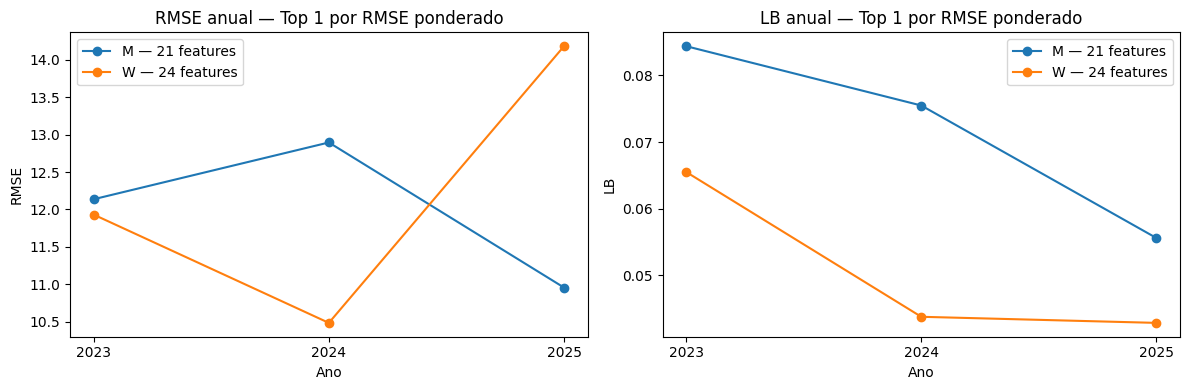

In [7]:
ranking=avaliador.ranking()
salvar_tabela('ranking.json',ranking)
mostrar_top(ranking,'Exp. 14 — Top 3 por RMSE ponderado, entre as combinações avaliadas')
if not ranking.empty:
    top=ranking.loc[ranking.Posicao.le(3)]
    anuais=['Categoria','Posicao','Configuracao','NFeatures','RMSE_2023','RMSE_2024','RMSE_2025',
            'RMSE_pond','RMSE_media','LB_2023','LB_2024','LB_2025','LB_pond']
    display(top[anuais])
    comparacao=top.merge(top13[['Configuracao','RMSE_pond','LB_pond']],on='Configuracao',
        suffixes=('','_exp13'),validate='many_to_one')
    equivalencia=auditoria_controle.assign(Equivalente=auditoria_controle.Status.eq('compativel_ok')).groupby(
        'Configuracao').Equivalente.all()
    comparacao['ControleEquivalenteExp13']=comparacao.Configuracao.map(equivalencia)
    comparacao['Delta_RMSE_vs_exp13']=np.where(comparacao.ControleEquivalenteExp13,
        comparacao.RMSE_pond-comparacao.RMSE_pond_exp13,np.nan)
    display(comparacao[['Categoria','Posicao','Configuracao','NFeatures','RMSE_pond','RMSE_pond_exp13',
        'Delta_RMSE_vs_exp13','LB_pond','LB_pond_exp13','ControleEquivalenteExp13']])
    print('Somente controles equivalentes permitem atribuir diferenças à seleção de features.')
    salvar_tabela('comparacao_exp13.json',comparacao)
    comuns=exp.comparar_categorias(ranking)
    for r in comuns.to_dict('records'):
        display(Markdown(f"**Top {r['Posicao']} — M: {r['NFeaturesM']} features | W: {r['NFeaturesW']} features**"))
        for col in ['MantidasAmbas','RemovidasSomenteM','RemovidasSomenteW','RemovidasAmbas']:
            display(HTML('<details><summary>'+escape(col+': '+str(len(r[col])))+
                '</summary><p>'+escape(', '.join(r[col]) or 'Nenhuma')+'</p></details>'))
    salvar_tabela('features_por_categoria.json',comuns)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,metrica in zip(axes,['RMSE','LB']):
        for r in top.loc[top.Posicao.eq(1)].to_dict('records'):
            ax.plot(ANOS,[r[f'{metrica}_{ano}'] for ano in ANOS],marker='o',
                label=f"{r['Categoria']} — {r['NFeatures']} features")
        ax.set(title=metrica+' anual — Top 1 por RMSE ponderado',xticks=ANOS,xlabel='Ano',ylabel=metrica)
        ax.legend()
    plt.tight_layout(); plt.show()


## Checkpoints, tempo e cobertura

O estado salva todos os subconjuntos e os três cortes, incluindo falhas, tempos,
recursos e etapas. Os arquivos de cada corte também preservam previsões e parâmetros.
Dados/versões/protocolo diferentes criam outro contexto; checkpoints antigos ficam
preservados. REPETIR_FALHAS=True repete somente falhas, sem refazer sucessos.


In [8]:
avaliacoes=list(avaliador.estado['avaliacoes'].values())
if avaliacoes:
    cobertura=pd.DataFrame(avaliacoes).groupby(['Categoria','Configuracao','status']).size().rename('Subconjuntos')
    display(cobertura)
    recursos=pd.DataFrame([{'Categoria':r['Categoria'],'Configuracao':r['Configuracao'],'Avaliacao':r['Candidato'],
        'NFeatures':r['NFeatures'],'Season':c['Season'],'status':c['status'],'erro':c.get('erro'),
        'segundos':0.,**(c.get('recursos') or {})} for r in avaliacoes for c in r.get('Cortes',[])])
    if not recursos.empty:
        display(recursos.groupby(['Categoria','Configuracao']).agg(Cortes=('Season','size'),
            Segundos=('segundos','sum')))
        salvar_tabela('recursos.json',recursos)
    print('Tempos reutilizados são históricos, não o custo desta execução.')
registro={'features_iniciais':FEATURES,'anos':ANOS,'seed':SEED,'n_folds':5,
    'pesos':REFERENCIAS.to_dict('records'),'versoes':comum.versoes(),'fontes':manifesto['fontes'],
    'candidatos':catalogo,'estado':str(avaliador.path_estado),'criterio':'RMSE ponderado',
    'piloto':{'ativo':RODAR_PILOTO,'features':PILOTO_FEATURES,'configuracoes_por_categoria':PILOTO_CONFIGURACOES_POR_CATEGORIA},
    'analise_completa':RODAR_ANALISE_COMPLETA,'progressiva':RODAR_PROGRESSIVA,
    'limites':{'avaliacoes_por_configuracao':MAX_AVALIACOES_POR_CONFIGURACAO,'max_removidas':MAX_FEATURES_REMOVIDAS,
        'min_features':MIN_FEATURES,'melhora_minima':MELHORA_MINIMA_RMSE}}
comum.salvar_json(CHECKPOINTS/'registro.json',registro)


Categoria  Configuracao                 status
M          M_tabpfn12_2973465e4981a4f7  ok        101
           M_tabpfn12_2c5a2f66d71abdc7  ok        101
           M_tabpfn12_33d31c0be877a927  ok        101
W          W_tabpfn12_66abb88e8a794c6e  ok         76
           W_tabpfn12_a727afef5f6e5059  ok         99
           W_tabpfn12_d1eec64c5c3daa7d  ok         76
Name: Subconjuntos, dtype: int64

Cortes    Segundos
Categoria Configuracao                                   
M         M_tabpfn12_2973465e4981a4f7     303  200.897050
          M_tabpfn12_2c5a2f66d71abdc7     303  201.697938
          M_tabpfn12_33d31c0be877a927     303  193.046012
W         W_tabpfn12_66abb88e8a794c6e     228  198.819450
          W_tabpfn12_a727afef5f6e5059     297  225.749259
          W_tabpfn12_d1eec64c5c3daa7d     228  204.603221

Tempos reutilizados são históricos, não o custo desta execução.


## Submissões opcionais

Somente quando GERAR_SUBMISSIONS=True. Retreinar com Season < 2026 e o subconjunto
próprio de cada combinação selecionada. Combinar Top 1 M/W, Top 2 M/W e Top 3 M/W.
Margens brutas, fallback zero, IDs e ordem do sample preservados. Nenhum envio ao Kaggle.


In [9]:
if GERAR_SUBMISSIONS:
    submissions=exp.gerar_submissions(avaliador,ranking,confrontos,sample,destino=raiz/'submissions')
    display(pd.DataFrame(submissions['submissions'])[
        ['Arquivo','NFeaturesM','NFeaturesW','ConfiguracaoM','ConfiguracaoW','Linhas','IdenticaA']])
    registro['submissions']=submissions
    comum.salvar_json(CHECKPOINTS/'registro.json',registro)
else:
    print('Treino final e geração de CSVs desativados. Habilite GERAR_SUBMISSIONS quando concluir a seleção.')


,Arquivo,NFeaturesM,NFeaturesW,ConfiguracaoM,ConfiguracaoW,Linhas,IdenticaA
0,submission_exp14_tabpfn_rmse_top1_2026.csv,21,24,M_tabpfn12_2c5a2f66d71abdc7,W_tabpfn12_66abb88e8a794c6e,132133,None
1,submission_exp14_tabpfn_rmse_top2_2026.csv,21,24,M_tabpfn12_2973465e4981a4f7,W_tabpfn12_d1eec64c5c3daa7d,132133,None
2,submission_exp14_tabpfn_rmse_top3_2026.csv,21,23,M_tabpfn12_33d31c0be877a927,W_tabpfn12_66abb88e8a794c6e,132133,None
